[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AndresOrdonez369/deepLearningWeek1/blob/main/semana3/proyectos/NB05_generalizar_y_robustez.ipynb)

# NB05 · Generalizar y ser robusto: ¿funcionará con casos nuevos?
**Neural Networks: Deep Learning · UIDE · Semana 3 · Tema 1** — Docente: Andrés Ordóñez-Bolaños

**La necesidad:** en la semana 2 la CNN sacó **87.7 %** en el examen final. Pero un modelo no se usa en el examen: se usa con **casos nuevos**, con fotos un poco movidas, con datos que cambian. Este Colab hace tres preguntas incómodas:
1. **¿Aprendió o memorizó?** Con pocas fotos, una red puede sacar casi 100 en lo que estudió y fallar lo nuevo. Le pondremos **frenos**.
2. **¿Aguanta un cambio pequeño?** Moveremos la foto unos píxeles y después le haremos un **cambio invisible** pensado para engañarla. Exacto no es lo mismo que robusto.
3. **¿Cómo elegimos los ajustes sin hacer trampa?** Afinaremos la red con el simulacro y miraremos el examen **una sola vez**.

### Cómo usar este Colab (2 minutos)
**Todo el código ya está escrito: tú lees, predices, ejecutas y comparas.** No tienes que programar nada para avanzar.

1. **Archivo → Guardar una copia en Drive.** Así tus cambios quedan guardados.
2. Ejecuta la celda **Configuración** y después avanza en orden con `Shift + Enter`.
3. Cada parte sigue el mismo orden:
   **Qué vas a hacer → la necesidad → ejemplo → el nombre → la fórmula («Léelo así») → Qué hace este código → 🔮 Antes de ejecutar: ¿qué crees que saldrá? → ejecuta → Qué deberías ver → 💭 Para pensar.**
4. En **🔮 Antes de ejecutar** detente cinco segundos y apuesta un resultado. Acertar no importa; **comparar** sí.
5. En **💭 Para pensar** responde con tu pareja y después abre **Ver respuesta**.
6. Las celdas **🧪 Experimenta** son opcionales: cambia **un solo** valor marcado y vuelve a ejecutar.
7. Al final hay **✍️ Ejercicios** (se responden leyendo tus resultados) y **10 preguntas** para comprobar que entendiste. **No tiene nota.** Trabajen en parejas y equivóquense sin miedo.

> **🛟 Si algo falla**
> - `NameError: name 'x' is not defined` → te saltaste una celda de arriba. Usa **Entorno de ejecución → Ejecutar anteriores** (o **Ejecutar todo**).
> - La descarga de las fotos falla (`URL fetch failure`) → espera unos segundos y vuelve a ejecutar la celda de la Parte 0.
> - Va lento → normal en CPU: el Colab completo tarda unos 4 minutos en la CPU de Colab (lo más largo son las Partes 3 y 5, alrededor de un minuto cada una). Si quieres, **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**.
> - Tus porcentajes difieren un poco de los de «Qué deberías ver» → normal: otra computadora (o la GPU) redondea distinto. Lo que importa es el **patrón**: qué sube, qué baja y cuánto.
> - Si cambiaste algo y ya no sabes qué: **Entorno de ejecución → Reiniciar y ejecutar todo**.

### Mapa del Colab
| Parte | Qué aprendes | Lámina |
|---|---|---|
| 0 | Los datos y la CNN de siempre (estudiar, simulacro y examen) | 6 |
| 1 | El estudiante que memoriza: 1 000 fotos y dos curvas que se separan | 9–10 |
| 2 | Frenos para la memoria: aumento, dropout y parar a tiempo (y más datos) | 11–14 |
| 3 | Mover la foto: el aumento de datos contra fotos corridas | 12, 15 |
| 4 | Engañar a la red: un ejemplo adversarial hecho a mano (FGSM) | 16–17 |
| 5 | Vacunar a la red: entrenamiento adversarial | 18–19 |
| 6 | Afinar sin hacer trampa: búsqueda al azar con el simulacro | 20 |
| 🏁 | Resumen · **✍️ Ejercicios** · **Para comprobar que entendiste** · **Experimento 5: ¿cuántas fotos?** | 21 |

En clase (lámina 21, unos 35 minutos): prioridad **1, 2 y 4**. La Parte 3 hay que **ejecutarla** (entrena la red que se ataca en la Parte 4), pero su lectura, la 5 y la 6 pueden quedar para casa.

In [1]:
# @title Configuración · ejecuta esta celda primero (no necesitas abrirla)
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # hide TensorFlow info messages
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

SEED = 2026
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

# The same colors as the slides: amber = training / attack, azure = validation, mint = with brakes / robust, coral = error
AMBAR, AZUL, MENTA, CORAL, TINTA, LILA = "#E39A12", "#2B8FD6", "#12A37F", "#E0533D", "#1F2A3A", "#8B6FD1"

# The 10 classes of Fashion-MNIST, in Spanish, in the order of the labels 0..9
CLASES = ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "zapatilla", "bolso", "botín"]

def ver(img, ax, title="", cmap="gray", vmin=0, vmax=1):
    # Draws a 28 x 28 image (values 0..1) without axes
    ax.imshow(np.squeeze(img), cmap=cmap, vmin=vmin, vmax=vmax); ax.set_title(title, fontsize=10); ax.axis("off")

def barras(probs, ax, title=""):
    # Horizontal bars with the 10 probabilities of a softmax; the largest one in amber
    colores = [AMBAR if i == int(np.argmax(probs)) else "#C9D3DE" for i in range(10)]
    ax.barh(CLASES, probs, color=colores); ax.set_xlim(0, 1.12); ax.invert_yaxis()
    ax.set_title(title, fontsize=10); ax.grid(axis="y", alpha=0)
    for i, p in enumerate(probs):
        if p > 0.02: ax.text(p + 0.01, i, f"{p:.0%}", va="center", fontsize=9)

print("Listo. TensorFlow", tf.__version__, "| Keras", keras.__version__)

Listo. TensorFlow 2.21.0 | Keras 3.15.1


---
## 0 · Los datos y la CNN de siempre
📽 Lámina 6

**Qué vas a hacer:** cargar las mismas 70 000 fotos de ropa de la semana 2 (Fashion-MNIST) y separar **tres grupos**, como en las semanas 1 y 2:

| Grupo | Para qué | Analogía |
|---|---|---|
| **Entrenamiento** | la red aprende con estas fotos | los ejercicios que estudias |
| **Validación** | medimos durante el camino, sin aprender de ellas | el **simulacro** |
| **Prueba** | se mira al final, una sola vez | el **examen final** |

Para ver el problema de memorizar usaremos a propósito **muy pocas fotos para estudiar: 1 000** (de las 60 000). El simulacro son 2 000 fotos que la red nunca estudia, y el examen, las 10 000 de prueba.

**La red:** la misma CNN del NB03 (semana 2): `Conv2D(16, 3)` → `MaxPooling2D(2)` → `Conv2D(32, 3)` → `MaxPooling2D(2)` → `Flatten` → `Dense(10, softmax)`. La escribimos como una **función** `cnn()` para poder armar variantes (con frenos, con más filtros) cambiando un solo argumento.

**Qué hace este código:**
- Carga las fotos, divide entre 255 (brillos entre 0 y 1) y agrega el eje del canal: forma `(28, 28, 1)`.
- Separa los tres grupos.
- Define `cnn()` y `mover()` (mueve todas las fotos `px` píxeles a la derecha; la usaremos en la Parte 3) y cuenta los parámetros de la CNN.

🔮 **Antes de ejecutar:** ¿recuerdas cuántos parámetros tenía la CNN del NB03?

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()   # downloads once
x_train = (x_train / 255.0).astype("float32")[..., None]   # 0..255 -> 0..1, and add the channel axis
x_test = (x_test / 255.0).astype("float32")[..., None]

# The three groups of Parts 1 and 2
x_small, y_small = x_train[:1000], y_train[:1000]           # 1 000 photos to study (on purpose, very few)
x_val, y_val = x_train[50000:52000], y_train[50000:52000]   # 2 000 photos for the simulacro (validation)
print("estudiar:", x_small.shape, "| simulacro:", x_val.shape, "| examen final:", x_test.shape)


def cnn(extra_in=(), drop=0.0, f1=16, f2=32):
    # The CNN from week 2. Options:
    #   extra_in: layers placed right after the input (for example, data augmentation)
    #   drop:     dropout rate before the last layer (0 = no dropout)
    #   f1, f2:   number of filters in the two convolutional layers
    L = [keras.Input(shape=(28, 28, 1)), *extra_in,
         layers.Conv2D(f1, 3, activation="relu"), layers.MaxPooling2D(2),
         layers.Conv2D(f2, 3, activation="relu"), layers.MaxPooling2D(2), layers.Flatten()]
    if drop:
        L.append(layers.Dropout(drop))                       # brake: switch off a random part of the neurons
    L.append(layers.Dense(10, activation="softmax"))         # 10 probabilities, one per class
    return keras.Sequential(L)


def mover(X, px):
    # Shifts every photo px pixels to the right; the empty columns on the left stay black (0)
    out = np.zeros_like(X)
    out[:, :, px:, :] = X[:, :, :-px, :]
    return out


print("parámetros de la CNN de siempre:", f"{cnn().count_params():,}")

estudiar: (1000, 28, 28, 1) | simulacro: (2000, 28, 28, 1) | examen final: (10000, 28, 28, 1)
parámetros de la CNN de siempre: 12,810


**Qué deberías ver:** `estudiar: (1000, 28, 28, 1) | simulacro: (2000, 28, 28, 1) | examen final: (10000, 28, 28, 1)` y **12 810** parámetros, los mismos del NB03.

---
## 1 · El estudiante que memoriza
📽 Láminas 9–10

**Qué vas a hacer:** entrenar la CNN **60 épocas** con solo 1 000 fotos y mirar dos curvas: la de lo que estudió y la del simulacro.

**La necesidad:** una red con 12 810 parámetros y solo 1 000 fotos tiene «memoria» de sobra. Puede aprenderse cada foto de entrenamiento de memoria, con sus detalles casuales (una arruga, un brillo), en vez de aprender **qué hace que un botín sea un botín**.

**Ejemplo:** el estudiante que se aprende de memoria el **solucionario** del examen pasado: saca 100 en los ejercicios que ya vio y falla los nuevos. Por eso existe el **simulacro**: ejercicios que no estudió.

**El nombre:** eso es el **sobreajuste** (*overfitting*). Se reconoce en las curvas: la pérdida de **entrenamiento sigue bajando**, pero la de **validación deja de bajar y empieza a subir**. La diferencia entre las dos exactitudes es la **brecha**:

$$\text{brecha} = \text{exactitud en entrenamiento} - \text{exactitud en validación}$$

**Léelo así:** "cuánto mejor le va con lo que estudió que con lo nuevo". Una brecha pequeña es normal; una brecha que **crece** época tras época es memoria.

**Qué hace este código:**
- `keras.utils.set_random_seed(SEED)` fija la semilla: todos arrancamos con los mismos pesos.
- Entrena 60 épocas con las 1 000 fotos y mide en el simulacro al final de cada época (`validation_data`).
- Dibuja las dos curvas de pérdida y de exactitud, y marca la época en que la pérdida de validación fue mínima.
- Al final, rinde el examen final (10 000 fotos).

🔮 **Antes de ejecutar:** al final de las 60 épocas, ¿qué exactitud crees que tendrá en las fotos que estudió? ¿Y en el simulacro?

entrenó en 15 s
época 60 · entrenamiento: 96.7% · simulacro: 83.0% · brecha: 13.7%
la pérdida del simulacro fue mínima en la época 33 (0.527); en la época 60 vale 0.585
examen final (10 000 fotos): 80.9%


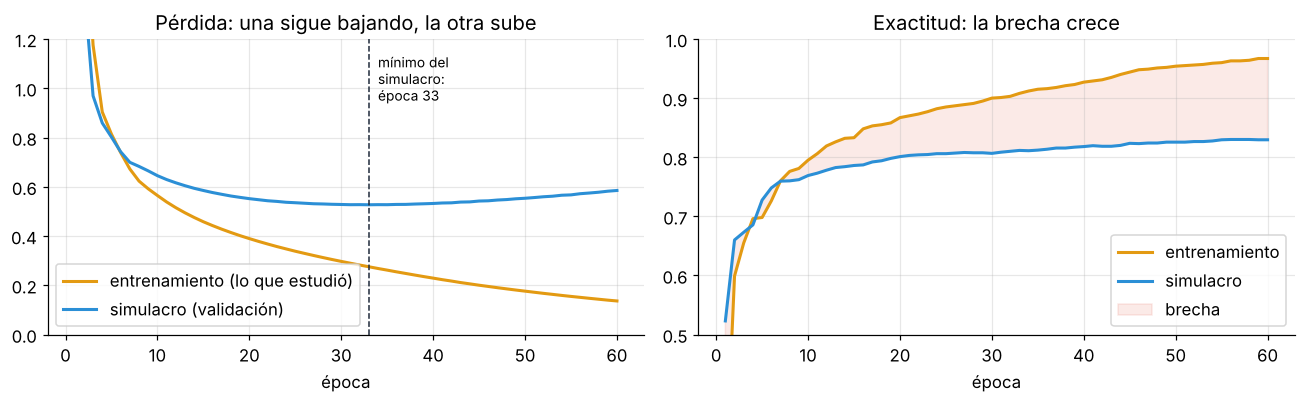

In [3]:
keras.utils.set_random_seed(SEED)                       # same starting weights for everyone
memoriza = cnn()                                        # the plain CNN: no brakes
memoriza.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
h1 = memoriza.fit(x_small, y_small, epochs=60, batch_size=64,
                  validation_data=(x_val, y_val), verbose=0)   # measure on the simulacro after every epoch
H1 = h1.history                                         # dictionary: loss, accuracy, val_loss, val_accuracy per epoch
mejor1 = int(np.argmin(H1["val_loss"])) + 1             # epoch (1, 2, ...) with the lowest validation loss
examen1 = memoriza.evaluate(x_test, y_test, verbose=0)[1]
print(f"entrenó en {time.time() - t0:.0f} s")
print(f"época 60 · entrenamiento: {H1['accuracy'][-1]:.1%} · simulacro: {H1['val_accuracy'][-1]:.1%} · brecha: {H1['accuracy'][-1] - H1['val_accuracy'][-1]:.1%}")
print(f"la pérdida del simulacro fue mínima en la época {mejor1} ({min(H1['val_loss']):.3f}); en la época 60 vale {H1['val_loss'][-1]:.3f}")
print(f"examen final (10 000 fotos): {examen1:.1%}")

ep = np.arange(1, 61)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(ep, H1["loss"], color=AMBAR, lw=2, label="entrenamiento (lo que estudió)")
axs[0].plot(ep, H1["val_loss"], color=AZUL, lw=2, label="simulacro (validación)")
axs[0].axvline(mejor1, color=TINTA, ls="--", lw=1); axs[0].text(mejor1 + 1, 0.95, f"mínimo del\nsimulacro:\népoca {mejor1}", fontsize=9)
axs[0].set_ylim(0, 1.2)                                 # zoom in: the first epochs (loss above 1.2) are cut off
axs[0].set_title("Pérdida: una sigue bajando, la otra sube"); axs[0].set_xlabel("época"); axs[0].legend(loc="lower left")
axs[1].plot(ep, H1["accuracy"], color=AMBAR, lw=2, label="entrenamiento")
axs[1].plot(ep, H1["val_accuracy"], color=AZUL, lw=2, label="simulacro")
axs[1].fill_between(ep, H1["val_accuracy"], H1["accuracy"], color=CORAL, alpha=0.12, label="brecha")
axs[1].set_ylim(0.5, 1.0); axs[1].set_title("Exactitud: la brecha crece"); axs[1].set_xlabel("época"); axs[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Qué deberías ver:** al final, alrededor de **96.7 %** en entrenamiento y **83.0 %** en el simulacro: una brecha de casi 14 puntos. La pérdida del simulacro es mínima cerca de la **época 33** (≈ 0.53) y después **sube** (≈ 0.58 en la época 60), mientras la de entrenamiento sigue bajando. En el examen final: alrededor de **80.9 %**, peor que el 87.7 % de la semana 2.

**Léelo así:** después de la época 33, cada época extra **empeora** a la red con lo nuevo: ya no aprende reglas generales, memoriza las 1 000 fotos.

### 💭 Para pensar

**1.** ¿En qué época habrías parado de entrenar, y con qué curva lo decidiste?

<details><summary>Ver respuesta</summary>

Cerca de la **época 33**, donde la pérdida del **simulacro** es mínima. Nunca con la curva de entrenamiento: esa siempre mejora. Es la idea del *early stopping* de la Parte 2.
</details>

**2.** Después de la época 33, la exactitud del simulacro casi no cambia, pero su pérdida sube. ¿Cómo puede ser?

<details><summary>Ver respuesta</summary>

La pérdida no solo cuenta aciertos: castiga la **seguridad** con que se equivoca. Al memorizar, la red se vuelve **demasiado segura**: en los casos nuevos que falla, falla con 99 % de confianza, y eso sube mucho la pérdida aunque la cantidad de aciertos sea parecida.
</details>

**3.** ¿Por qué 80.9 % en el examen y no el 96.7 % del entrenamiento?

<details><summary>Ver respuesta</summary>

Porque el examen son fotos **nuevas**, como el simulacro. El 96.7 % mide memoria; el 80.9 % mide lo que de verdad aprendió.
</details>

---
## 2 · Frenos para la memoria
📽 Láminas 11–14

**Qué vas a hacer:** entrenar **la misma red con las mismas 1 000 fotos**, pero con tres frenos, y comparar.

**La necesidad:** no siempre podemos conseguir más fotos. Necesitamos que la red **no pueda** depender de detalles casuales.

**El nombre:** todo lo que frena la memoria se llama **regularización**. Usaremos tres frenos:

| Freno | Qué hace | Analogía | En Keras |
|---|---|---|---|
| **Aumento de datos** | en cada época, mueve un poco cada foto al azar | practicar con la prenda movida: no te sorprende verla corrida | `layers.RandomTranslation(0.05, 0.05)` |
| **Dropout** | en cada paso, apaga al azar el 30 % de las neuronas de una capa | un equipo que entrena sabiendo que **puede faltar cualquiera**: nadie depende de un solo compañero | `layers.Dropout(0.3)` |
| **Parar a tiempo** (*early stopping*) | vigila el simulacro y para cuando deja de mejorar; se queda con la mejor época | dejar de estudiar cuando el simulacro empieza a salir peor | `keras.callbacks.EarlyStopping(...)` |

**La fórmula del dropout:** durante el entrenamiento, cada neurona $h_i$ de esa capa se convierte en

$$\tilde h_i = \begin{cases} 0 & \text{con probabilidad } p = 0.3 \\[2pt] \dfrac{h_i}{1-p} & \text{con probabilidad } 1 - p = 0.7 \end{cases}$$

**Léelo así:** "tres de cada diez neuronas se apagan, distintas en cada paso; las que quedan se agrandan un poco (÷ 0.7) para que la suma total no cambie". Al **predecir**, no se apaga ninguna.

**Ejemplo del aumento:** `RandomTranslation(0.05, 0.05)` mueve la foto hasta un 5 % de su alto y de su ancho: 0.05 × 28 ≈ **1.4 píxeles**, en una dirección al azar, distinta en cada época. La red nunca ve dos veces exactamente la misma foto.

**Qué hace este código:**
- Arma la CNN con `RandomTranslation(0.05, 0.05)` al principio y `Dropout(0.3)` antes de la última capa.
- `EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)`: si la pérdida del simulacro no mejora en **8 épocas seguidas**, para, y **devuelve los pesos de la mejor época**.
- Le da hasta 100 épocas (con frenos aprende más despacio) y compara con la red de la Parte 1.

🔮 **Antes de ejecutar:** ¿cuántos puntos crees que ganará en el examen final? ¿2, 5, 10?

entrenó en 21 s · se detuvo en la época 79 y se quedó con la 71
en la época 71 · entrenamiento: 87.9% · simulacro: 81.9%
examen final · sin frenos: 80.9% · con frenos: 81.6%


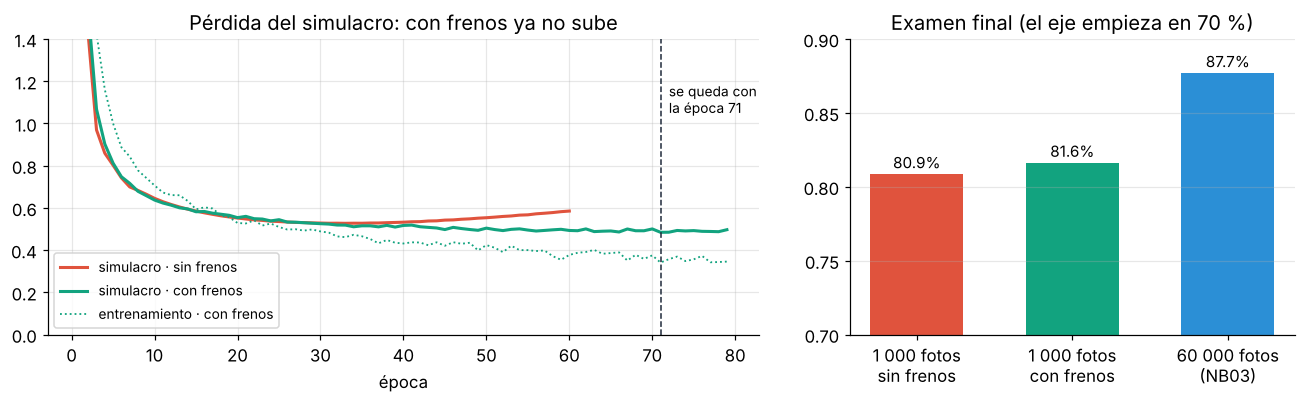

In [4]:
keras.utils.set_random_seed(SEED)
con_frenos = cnn(extra_in=(layers.RandomTranslation(0.05, 0.05),),   # brake 1: move each photo up to 5 % (about 1.4 px)
                 drop=0.3)                                            # brake 2: dropout 30 % before the last layer
con_frenos.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,  # brake 3: stop 8 epochs after the best one...
                                     restore_best_weights=True)       # ...and go back to the best weights

t0 = time.time()
h2 = con_frenos.fit(x_small, y_small, epochs=100, batch_size=64,
                    validation_data=(x_val, y_val), callbacks=[stop], verbose=0)
H2 = h2.history
mejor2 = int(np.argmin(H2["val_loss"])) + 1
examen2 = con_frenos.evaluate(x_test, y_test, verbose=0)[1]
print(f"entrenó en {time.time() - t0:.0f} s · se detuvo en la época {len(H2['loss'])} y se quedó con la {mejor2}")
print(f"en la época {mejor2} · entrenamiento: {H2['accuracy'][mejor2 - 1]:.1%} · simulacro: {H2['val_accuracy'][mejor2 - 1]:.1%}")
print(f"examen final · sin frenos: {examen1:.1%} · con frenos: {examen2:.1%}")

NB03 = 0.877     # the same CNN trained with the 60 000 photos (NB03, week 2); Part 3 trains it again
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
axs[0].plot(np.arange(1, 61), H1["val_loss"], color=CORAL, lw=2, label="simulacro · sin frenos")
axs[0].plot(np.arange(1, len(H2["val_loss"]) + 1), H2["val_loss"], color=MENTA, lw=2, label="simulacro · con frenos")
axs[0].plot(np.arange(1, len(H2["loss"]) + 1), H2["loss"], color=MENTA, lw=1.2, ls=":", label="entrenamiento · con frenos")
axs[0].axvline(mejor2, color=TINTA, ls="--", lw=1); axs[0].text(mejor2 + 1, 1.05, f"se queda con\nla época {mejor2}", fontsize=9)
axs[0].set_ylim(0, 1.4); axs[0].set_title("Pérdida del simulacro: con frenos ya no sube"); axs[0].set_xlabel("época"); axs[0].legend(fontsize=9)
nombres = ["1 000 fotos\nsin frenos", "1 000 fotos\ncon frenos", "60 000 fotos\n(NB03)"]
valores = [examen1, examen2, NB03]
axs[1].bar(nombres, valores, color=[CORAL, MENTA, AZUL], width=0.6)
for k, v in enumerate(valores): axs[1].text(k, v + 0.004, f"{v:.1%}", ha="center", fontsize=10)
axs[1].set_ylim(0.7, 0.9); axs[1].set_title("Examen final (el eje empieza en 70 %)"); axs[1].grid(axis="x", alpha=0)
plt.tight_layout(); plt.show()

**Qué deberías ver:** se detiene alrededor de la **época 79** y se queda con la **71**. En esa época, entrenamiento ≈ 87.9 % y simulacro ≈ 81.9 %: la brecha bajó de 14 a 6 puntos y las curvas de pérdida **ya no se separan** (la verde no sube). En el examen final: alrededor de **81.6 %** contra 80.9 %.

**Léelo así, con honestidad:** los frenos **controlan la memoria** (la brecha se cierra y no hay que adivinar cuándo parar), pero con 1 000 fotos ganan **poco** en el examen. La barra azul es la misma red con **las 60 000 fotos**: 87.7 %. **Más datos es el mejor freno**: ninguna técnica reemplaza ejemplos nuevos de verdad.

### 💭 Para pensar

**1.** ¿Por qué el dropout obliga a la red a aprender reglas más generales?

<details><summary>Ver respuesta</summary>

Porque en cada paso faltan neuronas distintas: ninguna puede ser la única que «se sabe» una foto. La información tiene que repartirse entre muchas neuronas, y lo que muchas aprenden juntas suele ser lo general, no el detalle casual.
</details>

**2.** `restore_best_weights=True`: ¿qué pasaría si lo pusiéramos en `False`?

<details><summary>Ver respuesta</summary>

La red se quedaría con los pesos de la **última** época (la 79), que ya llevaba 8 épocas sin mejorar en el simulacro. Con `True` vuelve a la **mejor** (la 71).
</details>

**3.** Si tuvieras que mejorar este modelo y te dan a elegir entre más frenos o 5 000 fotos más, ¿qué eliges?

<details><summary>Ver respuesta</summary>

Las **fotos**. Las cuentas de esta parte lo muestran: los frenos ganaron menos de un punto; pasar de 1 000 a 60 000 fotos ganó casi 7. (Lo verás también en el Experimento 5.) Los frenos sirven mucho cuando **no hay** más datos.
</details>

---
## 3 · Mover la foto: el aumento de datos contra fotos corridas
📽 Láminas 12, 15

**Qué vas a hacer:** entrenar dos CNN con **las 60 000 fotos** (5 épocas, como en el NB03), una sin aumento y otra con `RandomTranslation(0.15, 0.15)`, y tomarles el examen con las fotos **movidas** 1, 2, 3 y 4 píxeles.

**La necesidad:** en la semana 2 vimos que, con la prenda corrida 2 píxeles, la CNN bajaba de 87.7 % a ≈ 75 %. En la vida real las fotos nunca están perfectamente centradas: la cámara del celular, el pulso, el encuadre. Un modelo exacto en el examen puede ser **frágil** ante un cambio pequeño.

**El nombre:** aguantar cambios pequeños se llama **robustez**. Primera idea de la semana: **exacto no es lo mismo que robusto**.

**Ejemplo:** `RandomTranslation(0.15, 0.15)` mueve cada foto hasta 0.15 × 28 ≈ **4 píxeles** en cada eje, al azar y distinto en cada época:

$$\Delta_{\text{filas}},\ \Delta_{\text{columnas}} \sim \text{al azar entre } -4.2 \text{ y } +4.2 \text{ píxeles}$$

**Léelo así:** "cada vez que la red ve una foto, la ve corrida un poco hacia algún lado". Así practica con el mismo tipo de cambio que encontrará después.

**Qué hace este código (primera celda):** dibuja el primer botín de prueba movido 0, 1, 2, 3 y 4 píxeles con `mover()`: así se ven las fotos de este examen.

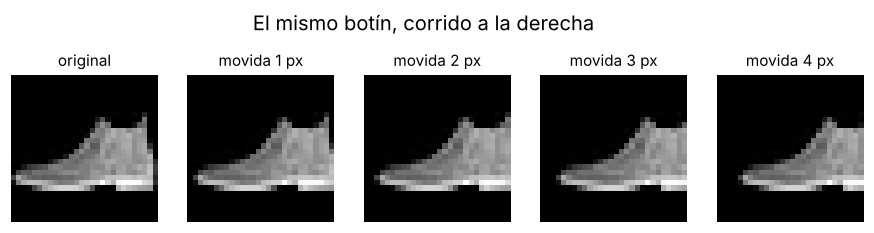

In [5]:
fig, axs = plt.subplots(1, 5, figsize=(10, 2.3))
ver(x_test[0], axs[0], "original")
for px, ax in zip((1, 2, 3, 4), axs[1:]):
    ver(mover(x_test[:1], px)[0], ax, f"movida {px} px")
plt.suptitle("El mismo botín, corrido a la derecha", y=1.04); plt.show()

**Qué hace este código (segunda celda):**
- Entrena las dos redes con el **mismo** código (un bucle con dos vueltas): la única diferencia es la capa `RandomTranslation(0.15, 0.15)` al principio.
- A cada una le toma el examen normal y el examen con las fotos movidas 1, 2, 3 y 4 píxeles.
- Guarda la red **sin** aumento como `base`: es la CNN del NB03 y la usaremos en las Partes 4 y 5.
- Tarda alrededor de un minuto en total.

🔮 **Antes de ejecutar:** con las fotos movidas 4 píxeles, ¿cuál crees que será la exactitud de cada red?

sin aumento  ·  23 s · 0 px: 87.7% · 1 px: 84.4% · 2 px: 75.2% · 3 px: 50.9% · 4 px: 28.2%


con aumento  ·  30 s · 0 px: 82.6% · 1 px: 82.6% · 2 px: 82.3% · 3 px: 81.1% · 4 px: 76.4%


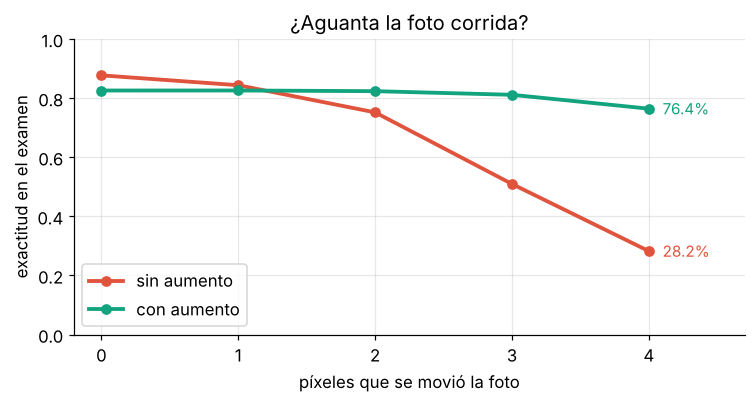

In [6]:
resultados = {}
for nombre, extra in [("sin aumento", ()), ("con aumento", (layers.RandomTranslation(0.15, 0.15),))]:
    t0 = time.time()
    keras.utils.set_random_seed(SEED)
    m = cnn(extra_in=extra)                                      # the only difference: the augmentation layer
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=0)
    exam = [m.evaluate(x_test, y_test, verbose=0)[1]]            # 0 px: the normal final exam
    exam += [m.evaluate(mover(x_test, px), y_test, verbose=0)[1] for px in (1, 2, 3, 4)]   # shifted photos
    resultados[nombre] = exam
    if nombre == "sin aumento":
        base = m                                                 # the NB03 CNN: Parts 4 and 5 attack it
    print(f"{nombre:12s} · {time.time() - t0:3.0f} s · " + " · ".join(f"{px} px: {a:.1%}" for px, a in enumerate(exam)))

fig, ax = plt.subplots(figsize=(7, 3.8))
for nombre, color in [("sin aumento", CORAL), ("con aumento", MENTA)]:
    ax.plot(range(5), resultados[nombre], "o-", color=color, lw=2.5, label=nombre)
    ax.text(4.1, resultados[nombre][4], f"{resultados[nombre][4]:.1%}", color=color, va="center", fontsize=10)
ax.set_xticks(range(5)); ax.set_xlabel("píxeles que se movió la foto"); ax.set_ylabel("exactitud en el examen")
ax.set_ylim(0, 1); ax.set_xlim(-0.2, 4.7); ax.set_title("¿Aguanta la foto corrida?"); ax.legend()
plt.tight_layout(); plt.show()

**Qué deberías ver:**

| | 0 px | 1 px | 2 px | 3 px | 4 px |
|---|---|---|---|---|---|
| **sin aumento** (la del NB03) | ≈ 87.7 % | 84.4 % | 75.2 % | 50.9 % | **28.2 %** |
| **con aumento** | ≈ 82.6 % | 82.6 % | 82.3 % | 81.1 % | **76.4 %** |

Sin aumento, la red se desploma: con 4 píxeles acierta menos de 3 de cada 10. Con aumento casi no se mueve. **El precio:** con las mismas 5 épocas, pierde unos 5 puntos con las fotos centradas (le pedimos aprender algo más difícil en el mismo tiempo).

**Léelo así:** el aumento compra **robustez** a cambio de unos puntos de exactitud. Cuál conviene depende de **cómo llegarán los datos** cuando se use el modelo.

**Qué hace este código (tercera celda):** muestra 6 versiones del mismo botín tal como las genera `RandomTranslation(0.15, 0.15)`: esto es lo que practicó la red con aumento. El espacio que queda vacío al mover la foto, Keras lo rellena **reflejando** la imagen como en un espejo (por eso a veces aparece un pedacito repetido en el borde).

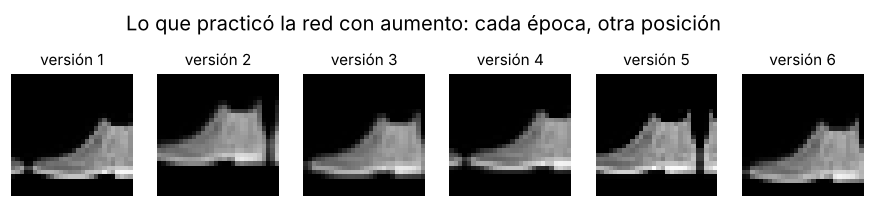

In [7]:
muestra = layers.RandomTranslation(0.15, 0.15, seed=SEED)        # a separate copy, only to look at it
vistas = muestra(np.repeat(x_test[:1], 6, axis=0), training=True)  # training=True: the shifts are applied
fig, axs = plt.subplots(1, 6, figsize=(10, 2))
for k, ax in enumerate(axs):
    ver(np.asarray(vistas[k]), ax, f"versión {k + 1}")
plt.suptitle("Lo que practicó la red con aumento: cada época, otra posición", y=1.06); plt.show()

### 💭 Para pensar

**1.** Tu modelo leerá fotos tomadas con el celular por los socios de una tienda. ¿Cuál de las dos redes eliges?

<details><summary>Ver respuesta</summary>

Probablemente la **con aumento**: las fotos del celular casi nunca estarán centradas, y ahí la red sin aumento puede caer a 28 %. Pero hay que **comprobarlo** con fotos reales de ese uso: el examen con fotos movidas a mano es solo una aproximación.
</details>

**2.** ¿Por qué no usamos `RandomTranslation(0.15)` en la Parte 2, con solo 1 000 fotos?

<details><summary>Ver respuesta</summary>

Porque con tan pocas fotos un movimiento tan grande vuelve la tarea demasiado difícil: la red no alcanza a aprender (se queda corta). Por eso allí usamos un movimiento suave (0.05). El aumento también es un **ajuste** que hay que elegir con el simulacro.
</details>

---
## 4 · Engañar a la red: un ejemplo adversarial hecho a mano
📽 Láminas 16–17

**Qué vas a hacer:** cambiar **muy poco** cada píxel del botín, de forma **invisible** para nosotros pero elegida para engañar a la red, y ver qué dice.

**La necesidad:** mover la foto es un cambio «natural». Pero, ¿y si alguien busca **a propósito** el cambio que más daño hace? Goodfellow, Shlens y Szegedy (2015) mostraron que basta con un ruido imperceptible para que una red se equivoque **con seguridad**. Es la segunda cara de «exacto no es robusto».

**Ejemplo: subir la montaña a propósito.** En la semana 1, el descenso de gradiente movía los **pesos cuesta abajo** en la pérdida para aprender. Ahora dejamos los pesos **quietos** y movemos un poquito cada **píxel cuesta arriba**, hacia donde la red se equivoca más.

**El nombre:** un **ejemplo adversarial**. El método más simple para fabricarlo es **FGSM** (*Fast Gradient Sign Method*):

$$x' = \text{recortar}_{[0,\,1]}\Big(x + \varepsilon \cdot \text{signo}\big(\nabla_x \text{pérdida}(x, y)\big)\Big)$$

**Léelo así:**
- $\nabla_x \text{pérdida}$: para cada píxel, **hacia dónde** hay que mover su brillo para que la pérdida suba (el gradiente de la semana 1, pero respecto de la **foto**, no de los pesos).
- $\text{signo}(\cdot)$: nos quedamos solo con la dirección: **+1** (aclarar) o **−1** (oscurecer).
- $\varepsilon$ (épsilon): **cuánto** se mueve cada píxel. Con $\varepsilon = 0.05$, cada brillo cambia 0.05, es decir, unos **13 de 255**.
- $\text{recortar}_{[0,1]}$: el brillo no puede salir de 0 a 1.

**Qué hace este código:**
- `tf.GradientTape()` es la «grabadora» de TensorFlow: anota las cuentas y después calcula el gradiente. `g.watch(x)` le pide gradientes **respecto de la foto**.
- `fgsm(model, X, y, eps)` aplica la fórmula a muchas fotos, de 2 000 en 2 000.
- Fabrica el ejemplo para el **primer botín** de prueba con $\varepsilon = 0.05$ y dibuja: la foto original, el cambio (agrandado para que se vea) y la foto engañosa, con lo que dice la red de cada una.

🔮 **Antes de ejecutar:** si a la vista son la misma foto, ¿crees que la red cambiará de opinión?

original : «botín» con 96%
engañosa : «zapatilla» con 67%  (y «botín» con 20%)
cambio por píxel: entre -0.05 y +0.05 (de una escala 0..1)


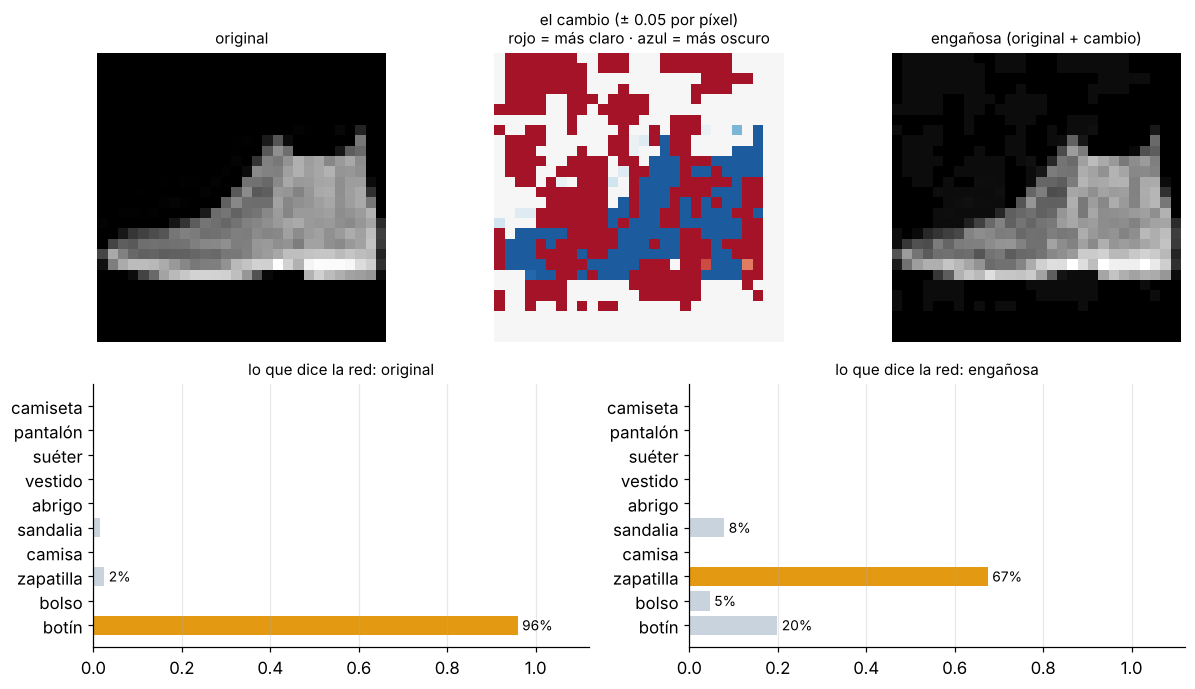

In [8]:
loss_fn = keras.losses.SparseCategoricalCrossentropy()      # the same loss used for training


def fgsm(model, X, y, eps, bs=2000):
    # Fast Gradient Sign Method: x' = clip(x + eps * sign(d loss / d x), 0, 1), in batches of bs photos
    out = []
    for i in range(0, len(X), bs):
        x = tf.convert_to_tensor(X[i:i + bs])               # the photos, as a TensorFlow tensor
        t = tf.convert_to_tensor(y[i:i + bs])               # their true labels
        with tf.GradientTape() as g:                        # "record" the computation...
            g.watch(x)                                      # ...and ask for gradients with respect to the PIXELS
            l = loss_fn(t, model(x, training=False))        # how wrong the network is on these photos
        grad = g.gradient(l, x)                             # for every pixel: which direction increases the loss
        out.append(tf.clip_by_value(x + eps * tf.sign(grad), 0, 1).numpy())   # one step UP the hill, kept in 0..1
    return np.concatenate(out)


x_adv = fgsm(base, x_test[:1], y_test[:1], 0.05)            # the first test photo (an ankle boot), eps = 0.05
p0 = base.predict(x_test[:1], verbose=0)[0]                 # probabilities for the original photo
p1 = base.predict(x_adv, verbose=0)[0]                      # probabilities for the deceptive photo
cambio = x_adv[0] - x_test[0]
print(f"original : «{CLASES[p0.argmax()]}» con {p0.max():.0%}")
print(f"engañosa : «{CLASES[p1.argmax()]}» con {p1.max():.0%}  (y «botín» con {p1[9]:.0%})")
print(f"cambio por píxel: entre {cambio.min():+.2f} y {cambio.max():+.2f} (de una escala 0..1)")

fig, axs = plt.subplot_mosaic([["o", "o", "d", "d", "a", "a"], ["po", "po", "po", "pa", "pa", "pa"]],
                              figsize=(11, 6.4), gridspec_kw={"height_ratios": [1.1, 1]})
ver(x_test[0], axs["o"], "original")
axs["d"].imshow(cambio[..., 0], cmap="RdBu_r", vmin=-0.06, vmax=0.06); axs["d"].axis("off")
axs["d"].set_title("el cambio (± 0.05 por píxel)\nrojo = más claro · azul = más oscuro", fontsize=10)
ver(x_adv[0], axs["a"], "engañosa (original + cambio)")
barras(p0, axs["po"], "lo que dice la red: original")
barras(p1, axs["pa"], "lo que dice la red: engañosa")
plt.tight_layout(); plt.show()

**Qué deberías ver:** con la foto original, **«botín» con 96 %**. Con la engañosa, **«zapatilla» con alrededor de 67 %** (y «botín» baja a ≈ 20 %). A la vista, las dos fotos son **la misma**: el cambio es de ± 0.05 por píxel, un ruido que casi no se nota. El mapa del medio muestra dónde aclaró (rojo) y dónde oscureció (azul); en blanco, los píxeles que no cambiaron (el fondo negro no puede oscurecerse más que 0). Parece ruido, pero está **calculado** para engañar: si miras con atención la foto engañosa, el fondo tiene manchitas grises.

### ¿Y con las 10 000 fotos?
**Qué hace este código:** fabrica la versión engañosa de **todo el examen** para cuatro valores de $\varepsilon$ (0.01, 0.02, 0.05 y 0.1) y mide la exactitud. Tarda unos segundos.

🔮 **Antes de ejecutar:** con $\varepsilon = 0.1$ (unos 26 de 255 por píxel), ¿qué exactitud crees que queda? Recuerda: el azar con 10 clases es 10 %.

ε:       0       0.01    0.02    0.05    0.1  
exactitud 87.7%  79.1%  69.1%  39.2%  13.0%


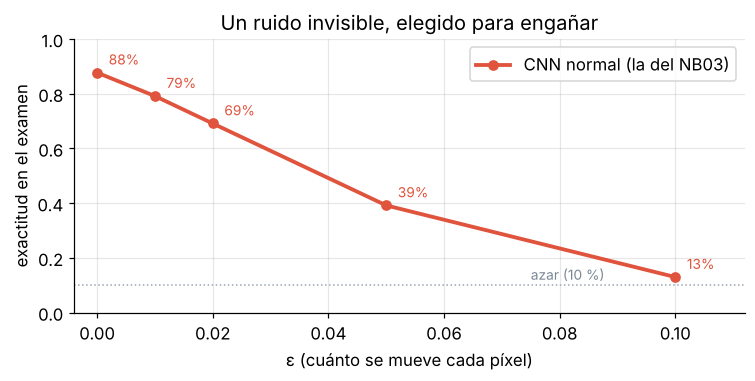

In [9]:
EPS = [0.01, 0.02, 0.05, 0.1]                               # how much each pixel may move
normal = [base.evaluate(x_test, y_test, verbose=0)[1]]      # eps = 0: the clean exam
for e in EPS:
    x_e = fgsm(base, x_test, y_test, e)                     # the deceptive version of the 10 000 photos
    normal.append(base.evaluate(x_e, y_test, verbose=0)[1])
print("ε:      ", "   ".join(f"{e:<5}" for e in [0] + EPS))
print("exactitud", "  ".join(f"{a:.1%}" for a in normal))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot([0] + EPS, normal, "o-", color=CORAL, lw=2.5, label="CNN normal (la del NB03)")
for e, a in zip([0] + EPS, normal): ax.text(e + 0.002, a + 0.03, f"{a:.0%}", color=CORAL, fontsize=9)
ax.axhline(0.1, color="#9AA6B2", ls=":", lw=1); ax.text(0.075, 0.12, "azar (10 %)", color="#7A8794", fontsize=9)
ax.set_xlabel("ε (cuánto se mueve cada píxel)"); ax.set_ylabel("exactitud en el examen"); ax.set_ylim(0, 1); ax.set_xlim(-0.004, 0.112)
ax.set_title("Un ruido invisible, elegido para engañar"); ax.legend(); plt.tight_layout(); plt.show()

**Qué deberías ver:** limpia ≈ **87.7 %** · $\varepsilon$ 0.01 → **79.1 %** · 0.02 → **69.1 %** · 0.05 → **39.2 %** · 0.1 → **13.0 %**, casi el azar. Con un cambio que a la vista no se nota (0.05), la red pasa de acertar casi 9 de cada 10 a menos de 4.

**Léelo así:** la red no «ve» un botín como nosotros: usa patrones de píxeles que un cambio pequeño **bien elegido** puede apagar o encender. Un 87.7 % no dice nada sobre esto.

### 💭 Para pensar

**1.** ¿En qué se parece y en qué se diferencia FGSM del descenso de gradiente de la semana 1?

<details><summary>Ver respuesta</summary>

Los dos usan el **gradiente de la pérdida**. El descenso mueve los **pesos** cuesta **abajo** (para aprender). FGSM deja los pesos quietos y mueve los **píxeles** cuesta **arriba** (para equivocarla).
</details>

**2.** Para fabricar estos ejemplos usamos el gradiente de **nuestra** red. ¿Por qué eso importa al pensar en un atacante real?

<details><summary>Ver respuesta</summary>

Porque es el peor caso: el atacante conoce la red por dentro (ataque de «caja blanca»). Un atacante sin acceso tiene que adivinar, pero se sabe que muchos ejemplos engañosos **se transfieren** a otras redes parecidas. Si un modelo decide algo importante (fotos de documentos, señales de tránsito), hay que medir esto.
</details>

---
## 5 · Vacunar a la red: entrenamiento adversarial
📽 Láminas 18–19

**Qué vas a hacer:** entrenar una CNN nueva que, en cada paso, estudia las fotos **y su versión engañosa**, y atacarla igual que en la Parte 4.

**La necesidad:** si sabemos cómo se engaña a la red, podemos **mostrarle** esos engaños mientras aprende.

**Ejemplo:** vacunarse. La vacuna te expone a una versión del virus para que tu cuerpo aprenda a reconocerlo.

**El nombre:** **entrenamiento adversarial** (Goodfellow et al., 2015). En cada lote de 128 fotos:
1. Con los pesos **de ese momento**, fabrica la versión FGSM de las 128 fotos ($\varepsilon = 0.05$).
2. Junta las 128 limpias y las 128 engañosas (256 fotos, con las mismas etiquetas).
3. Da **un paso** de aprendizaje con las 256.

$$\text{pérdida del lote} = \tfrac{1}{2}\Big(\text{pérdida}(x, y) + \text{pérdida}(x', y)\Big)$$

**Léelo así:** "la red se califica la mitad con las fotos limpias y la mitad con las engañosas": tiene que acertar las dos. Como $x'$ se fabrica con los pesos actuales, el engaño **se actualiza** a medida que la red aprende.

**Qué hace este código (paso a paso):**
- `adv = cnn()`: una CNN nueva, sin frenos, con la misma semilla.
- `paso_adversarial(x, y, eps)`: la receta del lote. La primera `GradientTape` calcula el gradiente **respecto de los píxeles** (como en la Parte 4) y fabrica `xa`; `tf.concat` junta limpias y engañosas; la segunda `GradientTape` calcula el gradiente **respecto de los pesos** y `opt.apply_gradients` da el paso (como `fit`, pero escrito a mano). `@tf.function` lo compila para que vaya más rápido.
- `ds`: las 60 000 fotos barajadas y en lotes de 128. Repite 5 épocas, es decir, 5 vueltas a todos los lotes. Tarda alrededor de un minuto.
- Al final de cada época imprime cuánto acierta en 2 000 fotos limpias de prueba, solo para ver que avanza.

🔮 **Antes de ejecutar:** con fotos limpias, ¿la red vacunada será mejor o peor que la normal (87.7 %)?

In [10]:
keras.utils.set_random_seed(SEED)
adv = cnn()                                                 # a new CNN, same architecture as base
opt = keras.optimizers.Adam()                               # the same optimizer that fit() uses with "adam"


@tf.function                                                # compile the step: much faster than plain Python
def paso_adversarial(x, y, eps):
    # 1) deceptive version of this batch, made with the CURRENT weights (gradient with respect to the pixels)
    with tf.GradientTape() as g:
        g.watch(x)
        l = loss_fn(y, adv(x, training=False))
    xa = tf.clip_by_value(x + eps * tf.sign(g.gradient(l, x)), 0, 1)
    # 2) clean photos + deceptive photos, with the same labels
    xx, yy = tf.concat([x, xa], 0), tf.concat([y, y], 0)
    # 3) one learning step on the 256 photos (gradient with respect to the weights)
    with tf.GradientTape() as g2:
        l2 = loss_fn(yy, adv(xx, training=True))
    opt.apply_gradients(zip(g2.gradient(l2, adv.trainable_variables), adv.trainable_variables))


ds = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(60000, seed=SEED).batch(128)   # 469 batches
t0 = time.time()
for ep in range(5):
    for xb, yb in ds:                                       # every batch of 128 photos
        paso_adversarial(xb, yb, 0.05)
    limpia = (adv.predict(x_test[:2000], verbose=0).argmax(1) == y_test[:2000]).mean()   # quick check only
    print(f"época {ep + 1} · {time.time() - t0:3.0f} s · acierta {limpia:.1%} de 2 000 fotos limpias")

época 1 ·   9 s · acierta 82.2% de 2 000 fotos limpias


época 2 ·  18 s · acierta 84.2% de 2 000 fotos limpias


época 3 ·  26 s · acierta 84.6% de 2 000 fotos limpias


época 4 ·  36 s · acierta 86.0% de 2 000 fotos limpias


época 5 ·  47 s · acierta 85.2% de 2 000 fotos limpias


**Qué hace este código:** toma el examen a la red vacunada, limpio y con los cuatro valores de $\varepsilon$. Cada ataque se fabrica **contra la propia red vacunada** (con su gradiente), para que la comparación sea justa. Después dibuja las dos curvas.

ε:        0       0.01    0.02    0.05    0.1  
normal    87.7%  79.1%  69.1%  39.2%  13.0%
vacunada  84.1%  81.6%  79.1%  71.7%  57.2%


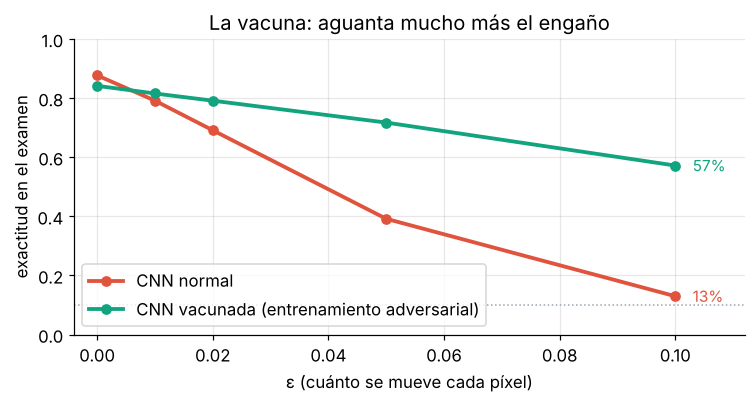

In [11]:
adv.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])   # only to use evaluate()
vacunada = [adv.evaluate(x_test, y_test, verbose=0)[1]]
for e in EPS:
    vacunada.append(adv.evaluate(fgsm(adv, x_test, y_test, e), y_test, verbose=0)[1])   # attack made against adv itself
print("ε:       ", "   ".join(f"{e:<5}" for e in [0] + EPS))
print("normal   ", "  ".join(f"{a:.1%}" for a in normal))
print("vacunada ", "  ".join(f"{a:.1%}" for a in vacunada))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot([0] + EPS, normal, "o-", color=CORAL, lw=2.5, label="CNN normal")
ax.plot([0] + EPS, vacunada, "o-", color=MENTA, lw=2.5, label="CNN vacunada (entrenamiento adversarial)")
for serie, color in [(normal, CORAL), (vacunada, MENTA)]:
    ax.text(0.103, serie[-1], f"{serie[-1]:.0%}", color=color, va="center", fontsize=10)
ax.axhline(0.1, color="#9AA6B2", ls=":", lw=1)
ax.set_xlabel("ε (cuánto se mueve cada píxel)"); ax.set_ylabel("exactitud en el examen"); ax.set_ylim(0, 1); ax.set_xlim(-0.004, 0.112)
ax.set_title("La vacuna: aguanta mucho más el engaño"); ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

**Qué deberías ver:** en las épocas, el acierto rápido en 2 000 fotos limpias ronda el 82–86 %. En el examen:

| ε | 0 (limpia) | 0.01 | 0.02 | 0.05 | 0.1 |
|---|---|---|---|---|---|
| **normal** | 87.7 % | 79.1 % | 69.1 % | 39.2 % | 13.0 % |
| **vacunada** | ≈ 84.1 % | 81.6 % | 79.1 % | **71.7 %** | 57.2 % |

Con $\varepsilon = 0.05$, la vacunada acierta **71.7 %** contra 39.2 %. **El precio:** unos 3.6 puntos menos con fotos limpias. Como con el aumento de datos: la robustez **se compra**.

**El mundo cambia (lámina 19):** en la práctica, el riesgo más común no es un atacante, sino un cambio **silencioso**: un modelo de crédito entrenado con socios urbanos que se usa con socios rurales, o uno entrenado antes de una crisis que se usa después. El modelo **no avisa**: sigue respondiendo con la misma seguridad. Por eso hay que **medir** con datos parecidos a los del uso real.

### 💭 Para pensar

**1.** ¿Por qué la vacunada pierde puntos con fotos limpias?

<details><summary>Ver respuesta</summary>

Porque la mitad de lo que estudia son fotos engañosas: con el mismo tiempo (5 épocas) dedica parte de su capacidad a resistir el engaño en vez de afinar los detalles de las fotos limpias. Robustez y exactitud a veces **compiten**.
</details>

**2.** Vacunamos con $\varepsilon = 0.05$. ¿Estará igual de protegida contra un ataque distinto (por ejemplo, mover la foto 4 píxeles)?

<details><summary>Ver respuesta</summary>

**No necesariamente.** Una vacuna protege contra lo que se parece a lo que se entrenó. Contra fotos movidas, lo que ayudó fue el aumento de datos (Parte 3). Cada tipo de cambio hay que **medirlo** por separado.
</details>

---
## 6 · Afinar sin hacer trampa: búsqueda al azar con el simulacro
📽 Lámina 20

**Qué vas a hacer:** probar 6 combinaciones de ajustes, elegir la mejor **con el simulacro** y tomar el examen final **una sola vez**.

**La necesidad:** hasta ahora elegimos a ojo el learning rate, los filtros y el dropout. ¿Y si había una combinación mejor? Probarlas todas es caro; probar **unas pocas al azar** suele funcionar sorprendentemente bien (Bergstra y Bengio, 2012).

**El nombre:** los **parámetros** (los pesos) los aprende la red; los **hiperparámetros** los elegimos nosotros **antes** de entrenar: learning rate, número de filtros, dropout, épocas… Buscarlos se llama **optimización de hiperparámetros**.

**Ejemplo:** afinar la guitarra. Se afina con el **simulacro**, nunca con el examen final. Si eliges la combinación mirando el examen, el examen deja de ser «casos nuevos»: ya lo usaste para decidir, y su nota sale **inflada**.

| Hiperparámetro | Valores posibles |
|---|---|
| learning rate | 0.0001 · 0.001 · 0.01 |
| filtros de la primera capa (la segunda usa el doble) | 8 · 16 · 32 |
| dropout | 0 · 0.3 |

Son 3 × 3 × 2 = 18 combinaciones; probaremos **6 al azar**.

**Qué hace este código:**
- Para que sea rápido: estudia con **10 000** fotos, **4 épocas**, y mide en un simulacro de **5 000** fotos que no estudia.
- `rng.choice` elige al azar cada valor (con semilla fija: a todos nos salen las mismas 6).
- Guarda la red con mejor simulacro y **solo esa** rinde el examen final.
- Tarda menos de un minuto.

🔮 **Antes de ejecutar:** ¿qué learning rate crees que gana? ¿Hay alguno que pueda fallar mucho con solo 4 épocas?

prueba 1 · lr 0.01   · filtros  8 · dropout 0.0 · simulacro 85.2% · 5,258 parámetros


prueba 2 · lr 0.001  · filtros 16 · dropout 0.0 · simulacro 81.0% · 12,810 parámetros


prueba 3 · lr 0.0001 · filtros 16 · dropout 0.3 · simulacro 69.3% · 12,810 parámetros


prueba 4 · lr 0.001  · filtros 32 · dropout 0.3 · simulacro 82.2% · 34,826 parámetros


prueba 5 · lr 0.01   · filtros 32 · dropout 0.3 · simulacro 86.8% · 34,826 parámetros


prueba 6 · lr 0.0001 · filtros 32 · dropout 0.3 · simulacro 72.6% · 34,826 parámetros

Gana la prueba 5 (elegida con el simulacro) · 36 s


Examen final, medido UNA sola vez con la ganadora: 86.9%


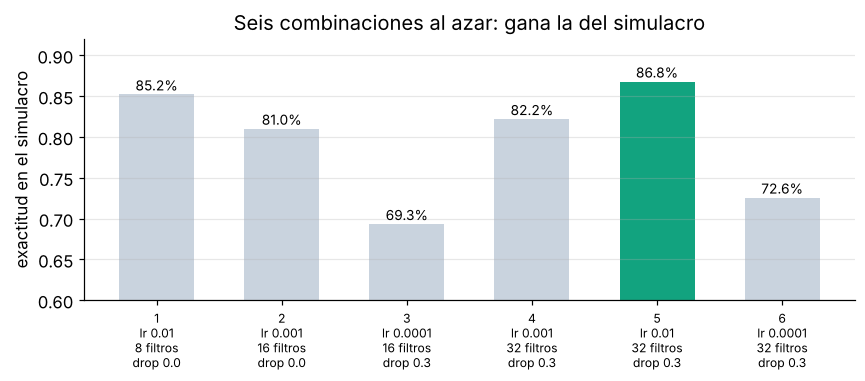

In [12]:
rng = np.random.default_rng(SEED)                                  # seeded: everyone gets the same 6 combinations
xs, ys = x_train[:10000], y_train[:10000]                          # 10 000 photos to study
xv, yv = x_train[50000:55000], y_train[50000:55000]                # 5 000 photos for the simulacro
pruebas = []
t0 = time.time()
for k in range(6):
    cfg = dict(lr=float(rng.choice([1e-4, 1e-3, 1e-2])),           # pick one value of each hyperparameter at random
               f1=int(rng.choice([8, 16, 32])),
               drop=float(rng.choice([0.0, 0.3])))
    keras.utils.set_random_seed(SEED)
    m = cnn(drop=cfg["drop"], f1=cfg["f1"], f2=2 * cfg["f1"])
    m.compile(optimizer=keras.optimizers.Adam(cfg["lr"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    m.fit(xs, ys, epochs=4, batch_size=128, verbose=0)
    cfg["val"] = m.evaluate(xv, yv, verbose=0)[1]                  # judged ONLY on the simulacro
    cfg["params"] = m.count_params()
    pruebas.append(cfg)
    if k == 0 or cfg["val"] > max(p["val"] for p in pruebas[:-1]):
        mejor_red = m                                              # keep the best network so far
    print(f"prueba {k + 1} · lr {cfg['lr']:<6} · filtros {cfg['f1']:2d} · dropout {cfg['drop']} · simulacro {cfg['val']:.1%} · {cfg['params']:,} parámetros")

g = int(np.argmax([p["val"] for p in pruebas]))
print(f"\nGana la prueba {g + 1} (elegida con el simulacro) · {time.time() - t0:.0f} s")
print(f"Examen final, medido UNA sola vez con la ganadora: {mejor_red.evaluate(x_test, y_test, verbose=0)[1]:.1%}")

fig, ax = plt.subplots(figsize=(8, 3.6))
etiquetas = [f"{k + 1}\nlr {p['lr']}\n{p['f1']} filtros\ndrop {p['drop']}" for k, p in enumerate(pruebas)]
ax.bar(range(6), [p["val"] for p in pruebas], color=[MENTA if k == g else "#C9D3DE" for k in range(6)], width=0.6)
for k, p in enumerate(pruebas): ax.text(k, p["val"] + 0.005, f"{p['val']:.1%}", ha="center", fontsize=9)
ax.set_xticks(range(6)); ax.set_xticklabels(etiquetas, fontsize=8); ax.set_ylim(0.6, 0.92)
ax.set_ylabel("exactitud en el simulacro"); ax.set_title("Seis combinaciones al azar: gana la del simulacro"); ax.grid(axis="x", alpha=0)
plt.tight_layout(); plt.show()

**Qué deberías ver:**

| Prueba | lr | filtros | dropout | Simulacro | Parámetros |
|---|---|---|---|---|---|
| 1 | 0.01 | 8 | 0 | 85.2 % | 5 258 |
| 2 | 0.001 | 16 | 0 | 81.0 % | 12 810 |
| 3 | 0.0001 | 16 | 0.3 | 69.3 % | 12 810 |
| 4 | 0.001 | 32 | 0.3 | 82.2 % | 34 826 |
| **5** | **0.01** | **32** | **0.3** | **86.8 %** | 34 826 |
| 6 | 0.0001 | 32 | 0.3 | 72.6 % | 34 826 |

Gana la **prueba 5**, y en el examen final, medido una sola vez, saca alrededor de **86.9 %**: muy cerca del simulacro, señal de que no hicimos trampa. Con solo 4 épocas, el learning rate pequeño (0.0001) **no alcanza** a aprender: da pasos demasiado cortos.

**Léelo así:** el learning rate pesó más que el número de filtros. Y la prueba 1, con **la séptima parte** de parámetros, quedó a 1.6 puntos de la ganadora.

### 💭 Para pensar

**1.** Un compañero probó las 6 combinaciones directamente en el examen final y reporta la mejor nota. ¿Qué tiene de malo?

<details><summary>Ver respuesta</summary>

Usó el examen para **decidir**: la nota que reporta es la mejor de 6 intentos y sale **inflada** por suerte. El examen deja de medir casos nuevos. Hay que elegir con el simulacro y mirar el examen **una vez**, al final.
</details>

**2.** Con 4 épocas ganó lr = 0.01. ¿Ganaría también con 50 épocas?

<details><summary>Ver respuesta</summary>

No lo sabemos: con más épocas, el learning rate pequeño tendría tiempo de llegar, y uno grande podría saltar de un lado a otro. **Los hiperparámetros dependen unos de otros** (y del presupuesto). Por eso se buscan juntos y se miden con el simulacro.
</details>

---
## 🏁 Resumen en 5 líneas
1. **Aprender no es memorizar:** con 1 000 fotos, entrenamiento 96.7 % y simulacro 83 %; la pérdida del simulacro **sube** desde la época 33. Eso es **sobreajuste**.
2. **Regularizar es ponerle frenos a la memoria:** aumento de datos, dropout y parar a tiempo cierran la brecha (81.6 % contra 80.9 %), pero **más datos** ayuda mucho más (87.7 %).
3. **Exacto no es robusto:** con la foto corrida 4 píxeles, la CNN cae de 87.7 % a 28.2 %; con un ruido invisible elegido a propósito (FGSM, ε = 0.05), a 39.2 %.
4. **La robustez se compra:** el aumento (76.4 % con 4 px) y el entrenamiento adversarial (71.7 % con ε = 0.05) protegen a cambio de unos puntos con fotos limpias.
5. **Afinar sin trampa:** los hiperparámetros se eligen con el **simulacro**; el examen final se mira **una sola vez** (86.9 %).

## ✍️ Ejercicios

Se responden **leyendo los resultados de este notebook y pensando**: no hay que programar nada. Escribe tu respuesta (dos a cinco líneas) en una celda de texto debajo de cada uno y después compárala con la respuesta plegada.

**Ejercicio 1.** **Leer una curva.** Mira las dos gráficas de pérdida (Partes 1 y 2). Explica con tus palabras por qué en la Parte 1 la curva del simulacro tiene forma de «U» y en la Parte 2 no. ¿Qué parte de la «U» es aprender y qué parte es memorizar?

<details><summary>Ver una respuesta posible</summary>

En la Parte 1, la pérdida del simulacro baja hasta la época ≈ 33 (la red aprende reglas que también sirven en fotos nuevas) y después **sube** (la red memoriza detalles de las 1 000 fotos y se vuelve demasiado segura en sus errores). La bajada es aprender; la subida, memorizar. En la Parte 2, el dropout y el aumento impiden memorizar y el *early stopping* corta la curva antes de que suba: por eso no hay «U».
</details>

**Ejercicio 2.** **¿Sirven los frenos?** Un colega mira la Parte 2 y dice: «con frenos solo gané 0.7 puntos, no sirven para nada». Con los números de las Partes 2 y 3, escribe qué le responderías.

<details><summary>Ver una respuesta posible</summary>

Tiene razón en que con 1 000 fotos la mejora en el examen es pequeña (80.9 → 81.6 %), pero los frenos hicieron dos cosas: **controlaron la memoria** (la brecha bajó de ≈ 14 a ≈ 6 puntos y el modelo eligió solo cuándo parar) y, en la Parte 3, el aumento de datos dio **robustez**: con la foto movida 4 píxeles, 76.4 % contra 28.2 %. Además, la lección honesta es que **más datos** (87.7 %) es el mejor freno: si se pueden conseguir, primero datos.
</details>

**Ejercicio 3.** **Elegir con criterio.** Tienes que entregar una de estas tres redes a una tienda que fotografía la ropa con el celular: la normal (Parte 3, sin aumento), la de aumento (Parte 3) o la vacunada (Parte 5). Usa las tablas de este notebook para justificar tu elección y di qué medirías **antes** de entregarla.

<details><summary>Ver una respuesta posible</summary>

La **de aumento** parece la mejor opción: en ese uso las fotos llegan corridas, y ahí aguanta (76.4 % con 4 px contra 28.2 %), aunque pierde ≈ 5 puntos con fotos centradas. La vacunada protege contra un **atacante** (FGSM), que en una tienda es un riesgo menor, y no la medimos con fotos movidas. Antes de entregarla mediría con **fotos reales del celular** de la tienda (no solo con fotos movidas a mano), y por clase (camisa contra camiseta), porque el examen de Fashion-MNIST no es el mundo real.
</details>

**Ejercicio 4.** **¿Dónde está la trampa?** Un equipo reporta: «probamos 18 combinaciones de hiperparámetros, elegimos la mejor por su nota en el examen final y obtuvimos 89 %». Con lo que hiciste en la Parte 6, explica qué número **no** deberían reportar, qué número sí, y por qué en la Parte 6 la nota del examen (86.9 %) quedó tan cerca de la del simulacro (86.8 %).

<details><summary>Ver una respuesta posible</summary>

No deberían reportar el 89 %: es la **mejor de 18 notas** del examen, elegida mirando el examen, así que está inflada por suerte. Deberían elegir con un **simulacro** y reportar la nota del examen de **esa sola** red, medida una vez. En la Parte 6, el examen quedó cerca del simulacro porque el examen no participó en la decisión: es una medida honesta de casos nuevos.
</details>

---
## 🏁 Para comprobar que entendiste
Responde cada pregunta **antes** de abrir la respuesta. Si fallas alguna, vuelve a la parte indicada.

### 💭 Preguntas

**1.** ¿Para qué sirve cada grupo: entrenamiento, validación (simulacro) y prueba (examen final)?

<details><summary>Ver respuesta</summary>

Con el **entrenamiento** la red aprende; con la **validación** decidimos (cuándo parar, qué ajustes usar) sin que la red aprenda de ella; la **prueba** se mira al final, una vez, para saber cómo le irá con casos nuevos. (Parte 0)
</details>

**2.** ¿Qué señal de las curvas te dice que una red está memorizando?

<details><summary>Ver respuesta</summary>

La pérdida de **entrenamiento sigue bajando** mientras la de **validación deja de bajar y sube**; la brecha entre las exactitudes crece. (Parte 1)
</details>

**3.** ¿Qué hace `Dropout(0.3)` durante el entrenamiento? ¿Y al predecir?

<details><summary>Ver respuesta</summary>

Al entrenar, en cada paso **apaga al azar el 30 %** de las neuronas de esa capa (y agranda las demás ÷ 0.7). Al predecir **no apaga ninguna**. (Parte 2)
</details>

**4.** En `EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)`, ¿qué significa cada argumento?

<details><summary>Ver respuesta</summary>

`monitor`: vigila la pérdida del simulacro. `patience=8`: espera 8 épocas sin mejora antes de parar. `restore_best_weights=True`: al parar, vuelve a los pesos de la **mejor** época. (Parte 2)
</details>

**5.** Según este notebook, ¿qué ayudó más en el examen final: los frenos o más fotos?

<details><summary>Ver respuesta</summary>

**Más fotos**: los frenos llevaron de 80.9 % a 81.6 %; la misma red con 60 000 fotos llega a 87.7 %. (Partes 2 y 3)
</details>

**6.** ¿Qué compró y qué costó el aumento de datos con `RandomTranslation(0.15)`?

<details><summary>Ver respuesta</summary>

Compró **robustez** ante fotos corridas (76.4 % contra 28.2 % con 4 px) y costó unos 5 puntos con fotos centradas (82.6 % contra 87.7 %) con las mismas 5 épocas. (Parte 3)
</details>

**7.** En la fórmula de FGSM, ¿qué hacen $\text{signo}(\nabla_x \text{pérdida})$ y $\varepsilon$?

<details><summary>Ver respuesta</summary>

El **signo del gradiente** dice, para cada píxel, si aclararlo (+1) u oscurecerlo (−1) para que la pérdida **suba**. **ε** dice cuánto se mueve cada píxel (0.05 ≈ 13 de 255). (Parte 4)
</details>

**8.** ¿Qué diferencia hay entre el gradiente que usa el entrenamiento y el que usa FGSM?

<details><summary>Ver respuesta</summary>

El entrenamiento usa el gradiente **respecto de los pesos** y baja la pérdida; FGSM usa el gradiente **respecto de los píxeles** y la sube, con los pesos quietos. (Parte 4)
</details>

**9.** ¿Qué hace el entrenamiento adversarial en cada lote, y qué precio pagó la red vacunada?

<details><summary>Ver respuesta</summary>

Fabrica la versión FGSM del lote con los pesos actuales, la junta con las fotos limpias y da un paso con las dos. Con ε = 0.05 pasó de 39.2 % a 71.7 %, a cambio de bajar de 87.7 % a 84.1 % con fotos limpias. (Parte 5)
</details>

**10.** ¿Por qué los hiperparámetros se eligen con el simulacro y no con el examen final?

<details><summary>Ver respuesta</summary>

Porque si el examen se usa para decidir, deja de medir casos nuevos y su nota sale **inflada**. Se afina con el simulacro y el examen se mira **una sola vez** (86.9 %). (Parte 6)
</details>

---
### 🧪 Experimento 5 (opcional): ¿cuántas fotos hacen falta?
📽 Lámina 21

**La pregunta:** en la Parte 2 dijimos que **más datos es el mejor freno**. ¿Cuánto mejora la misma red con frenos si le damos más fotos para estudiar?

**Qué hace este código:**
- `n_fotos = 1000` decide cuántas fotos estudia (las primeras `n_fotos` de entrenamiento). El simulacro y el examen no cambian.
- Arma la red con los tres frenos de la Parte 2 y la entrena con las mismas reglas (hasta 100 épocas, *early stopping*).
- Muestra en qué época se detuvo y la exactitud en el examen final.

🔮 **Antes de ejecutar (con `n_fotos = 3000`):** ¿cuántos puntos crees que gana respecto de las 1 000 fotos (81.6 %)?

In [13]:
n_fotos = 1000                                     # photos to study   (🧪 try 3000, then 10000)

keras.utils.set_random_seed(SEED)
exp = cnn(extra_in=(layers.RandomTranslation(0.05, 0.05),), drop=0.3)   # the network with brakes from Part 2
exp.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
t0 = time.time()
he = exp.fit(x_train[:n_fotos], y_train[:n_fotos], epochs=100, batch_size=64,
             validation_data=(x_val, y_val), callbacks=[stop], verbose=0)
print(f"{n_fotos:,} fotos · se detuvo en la época {len(he.history['loss'])} · {time.time() - t0:.0f} s · "
      f"examen final: {exp.evaluate(x_test, y_test, verbose=0)[1]:.1%}")

1,000 fotos · se detuvo en la época 79 · 28 s · examen final: 81.6%


**Qué deberías ver:** con `n_fotos = 1000`, la misma red de la Parte 2: se detiene en la época **79** y saca alrededor de **81.6 %**.

Con `3000`: se detiene en la época ≈ 84 y llega a alrededor de **85.6 %**: cuatro puntos más, cuando los tres frenos juntos ganaron 0.7. Con `10000`: se detiene en la época ≈ 54 (tarda ≈ 1 minuto) y llega a alrededor de **87.0 %**, casi lo mismo que la red **sin frenos** con las 60 000 fotos (87.7 %).

🧪 **Experimenta:** cambia `n_fotos = 1000` por `3000` y ejecuta otra vez; después prueba `10000`. Anota la exactitud de cada una: ¿cuántas fotos ganan lo mismo que todos los frenos juntos?

### 💭 Para pensar

**1.** ¿Qué aprendiste de este experimento sobre los frenos y los datos?

<details><summary>Ver respuesta</summary>

Que los frenos ayudan, pero **los datos ayudan mucho más**. Cuando un proyecto tiene pocos datos, a veces la mejor inversión no es una técnica nueva, sino conseguir (o etiquetar) más ejemplos.
</details>

**2.** Si conseguir fotos nuevas es imposible, ¿qué otra idea del curso podría ayudar?

<details><summary>Ver respuesta</summary>

Reutilizar lo que **otra red ya aprendió** con muchas fotos: el **transfer learning**, el primer tema del NB06.
</details>

---
**¿Te quedó alguna duda?** Repasa las slides interactivas y la guía de estudio desde la página del curso (Semana 3). En el Tema 2 (NB06) la pregunta cambia: **¿puedo reutilizar lo que otra red aprendió, y explicar lo que decide?** Lee antes la lectura de tendencia, «¿Puedes explicar por qué tu modelo dijo «no»?».